# 03 · Nettoyage des données raw (20 bâtiments)

**Objectif** : transformer l'électricité *raw* des 20 bâtiments retenus en un jeu **propre, documenté et sans fuite de données**, prêt pour le machine learning.

**Méthode en 4 temps, pour chaque problème** :
1. **Détecter** : on construit un *masque* (True = valeur suspecte), on ne modifie rien ;
2. **Regarder** : graphiques, comptages, sensibilité au seuil ;
3. **Décider** : un seuil, une raison, une alternative écartée (à noter pour l'ADR) ;
4. **Corriger** : seulement ensuite.

**Principes anti-fuite** (à respecter pour tout le projet) :
- aucun seuil n'est choisi en regardant les résultats d'un modèle ni la période de test 2017 ;
- aucune valeur à prédire n'est inventée : les valeurs interpolées sont **marquées** (`kwh_imputed`) pour être exclues de l'évaluation ;
- le fichier `cleaned` des auteurs sert de **référence de comparaison**, jamais d'entrée.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")                       # ce notebook s'exécute depuis notebooks/
RAW = ROOT / "data" / "raw" / "bdg2"    # fichiers téléchargés (jamais modifiés, jamais dans Git)
INTERIM = ROOT / "data" / "interim"     # résultats intermédiaires (hors Git)
PROCESSED = ROOT / "data" / "processed" # jeu final (hors Git, DVC en S7)
for dossier in (INTERIM, PROCESSED):
    dossier.mkdir(parents=True, exist_ok=True)

SEED = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def runs(masque):
    """Pour chaque heure où masque est True : longueur de la série de True qui la contient (0 sinon).
    Exemple : [F, T, T, T, F, T] -> [0, 3, 3, 3, 0, 1]"""
    groupe = (masque != masque.shift()).cumsum()
    return masque.groupby(groupe).transform("sum") * masque

def dominant(serie):
    """Valeur la plus fréquente d'une colonne (ou 'inconnu' si tout est vide)."""
    vc = serie.value_counts()
    return vc.index[0] if len(vc) else "inconnu"

def plus_long_trou(serie):
    """Plus longue suite d'heures manquantes consécutives."""
    return int(runs(serie.isna()).max())

In [3]:
params = json.loads((INTERIM / "selection-params.json").read_text(encoding="utf-8"))
ids = pd.read_csv(INTERIM / "batiments-retenus.csv")
SITE, choisis = params["site"], ids["building_id"].tolist()
print(f"Site {SITE} · {len(choisis)} bâtiments")

# usecols : on ne lit QUE les colonnes voulues (rapide, peu de mémoire)
lire = dict(usecols=["timestamp"] + choisis, parse_dates=["timestamp"], index_col="timestamp")
X = pd.read_csv(RAW / "electricity.csv", **lire)                 # à nettoyer
REF = pd.read_csv(RAW / "electricity_cleaned.csv", **lire)       # référence (comparaison seulement)
assert X.shape[1] == len(choisis), "Des bâtiments retenus sont absents du fichier raw."
assert X.index.equals(REF.index), "Les index de raw et cleaned diffèrent."
X.shape

Site Fox · 20 bâtiments


(17544, 20)

### Cohérence du contenu entre `raw` et `cleaned`

Le `cleaned` des auteurs ne fait que **remplacer des valeurs par NaN**. Là où il a une valeur, elle doit donc être **identique** à celle de `raw`. Si ce n'est pas le cas, l'un des deux fichiers a été modifié (par exemple réenregistré dans Excel avec des arrondis) ou les auteurs ont fait une autre transformation. Ce contrôle porte sur le **contenu**, quelle que soit la taille des fichiers.

In [4]:
communes = X.notna() & REF.notna()
ecart = (X - REF).abs().where(communes)
part_egale = ((ecart <= 1e-6) & communes).sum().sum() / communes.sum().sum() * 100
print(f"valeurs communes identiques entre raw et cleaned : {part_egale:.4f} %  ({int(communes.sum().sum()):,} valeurs comparées)".replace(",", " "))
print("valeurs présentes dans cleaned mais absentes de raw :", int((REF.notna() & X.isna()).sum().sum()))
print("écart maximal entre valeurs communes :", float(ecart.max().max()))
print("VERDICT :", "contenu cohérent" if part_egale > 99.99 else "À EXAMINER : raw ou cleaned a été modifié (voir le bâtiment le plus écarté ci-dessous)")
(ecart > 1e-6).sum().sort_values(ascending=False).head(5).to_frame("nb valeurs différentes")

valeurs communes identiques entre raw et cleaned : 100.0000 %  (350 152 valeurs comparées)
valeurs présentes dans cleaned mais absentes de raw : 0
écart maximal entre valeurs communes : 0.0
VERDICT : contenu cohérent


,nb valeurs différentes
Fox_lodging_Stephen,0
Fox_education_Andre,0
Fox_education_Charles,0
Fox_office_Margarita,0
Fox_office_Berniece,0


## 1. Contrôles de structure

Index trié, sans doublon, pas de 1 h régulier, nombre d'heures par jour (détection d'un éventuel saut d'heure d'été).

### Doublons dans les 20 bâtiments

Deux colonnes presque identiques (corrélation > 0,999) sont la même série comptée deux fois : à retirer avant de continuer.

In [5]:
corr = X.corr().abs()
paires = [(a, b, round(corr.loc[a, b], 5)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if corr.loc[a, b] > 0.999]
print("paires quasi identiques :", paires if paires else "aucune")

paires quasi identiques : aucune


In [6]:
attendu = pd.date_range(X.index.min(), X.index.max(), freq="h")
controles = {
    "index trié": X.index.is_monotonic_increasing,
    "index sans doublon": X.index.is_unique,
    "aucune heure manquante": len(attendu.difference(X.index)) == 0,
    "17 544 heures": len(X) == 17544,
}
print(pd.Series(controles))
assert all(controles.values()), "Un contrôle de structure échoue : à investiguer avant d'aller plus loin."
print(X.index.to_series().groupby(X.index.normalize()).size().value_counts())

index trié                True
index sans doublon        True
aucune heure manquante    True
17 544 heures             True
dtype: bool
timestamp
24    731
Name: count, dtype: int64


## 2. État initial : ce que contient raw

Combien de valeurs manquantes, négatives, nulles par bâtiment avant tout nettoyage ?

In [7]:
avant = pd.DataFrame({
    "pct_nan": X.isna().mean() * 100,
    "nb_negatifs": (X < 0).sum(),
    "nb_zeros": (X == 0).sum(),
    "kwh_median": X.median(),
    "kwh_max": X.max(),
})
avant.describe().T

,count,mean,std,min,25%,50%,75%,max
pct_nan,20.00,0.12,0.37,0.01,0.01,0.01,0.07,1.67
nb_negatifs,20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
nb_zeros,20.00,14.75,37.03,0.00,2.00,5.00,9.50,170.00
kwh_median,20.00,120.94,134.41,9.69,18.14,83.85,164.00,447.06
kwh_max,20.00,236.69,207.60,42.20,74.70,153.26,323.47,656.25


## 3. Détection (masques)

Quatre règles, appliquées **dans cet ordre** (chacune voit les données privées des défauts déjà repérés) :

| Règle | Idée | Pourquoi |
|---|---|---|
| Négatif | kWh < 0 | un compteur de consommation ne devrait pas être négatif |
| Zéros longs | ≥ `ZERO_H` heures de zéros d'affilée | un bâtiment ne s'éteint pas totalement : compteur en panne ou donnée absente |
| Valeur figée | même valeur ≥ `FIGE_H` heures d'affilée | un vrai bâtiment fluctue ; compteur bloqué |
| Aberrante | écart robuste à la médiane de la même heure et du même jour de semaine (± 2 semaines) > `K` × MAD | pics absurdes, tout en tolérant le cycle jour/semaine et la saison |

> **Les seuils ci-dessous sont provisoires.** On les ajuste avec les graphiques des sections 4 et 5, puis on les fige.

In [8]:
# --- SEUILS (provisoires, révisés après la première exécution sur Fox) ---
ZERO_H = 1           # tout zéro est une donnée manquante (les auteurs de BDG2 retirent 483 zéros sur 483 pour ces 20 bâtiments)
FIGE_H = 24          # même valeur non nulle pendant 24 h d'affilée (à confirmer avec la sensibilité de la section 4)
FIGE_RESOLUTION_MIN = 100  # compteur à faible résolution (moins de 100 valeurs distinctes) : les plateaux sont normaux, la règle ne s'applique pas
RETIRER_ABERRANTS = False  # on ne retire PAS les aberrants : 0 confirmé par les auteurs, pas de coude dans la sensibilité, risque d'effacer de vrais pics (événements)
K = 15               # multiple de l'échelle robuste (MAD) pour les aberrants (à confirmer avec la sensibilité de la section 5)
TROU_INTERP_H = 3    # trous <= 3 h interpolés (voir section 7)
METEO_INTERP_H = 6   # trous de météo <= 6 h interpolés
METEO_MAX_NAN = 40   # % de NaN au-delà duquel une variable météo est écartée

In [9]:
def masques_simples(X):
    negatif = X < 0
    zeros_long = (X == 0).apply(runs) >= ZERO_H
    fige = ((X.diff() == 0) & (X != 0)).apply(runs) >= FIGE_H
    fige.loc[:, X.nunique() < FIGE_RESOLUTION_MIN] = False     # faible résolution : plateaux normaux, on ne les retire pas
    return negatif, zeros_long, fige

def ecart_robuste(X):
    """Écart de chaque valeur à la médiane glissante (même heure, même jour de semaine, ± 2 semaines),
    et échelle robuste par bâtiment (MAD x 1,4826). Médiane centrée : sert à MARQUER, pas à prédire."""
    g = [X.index.dayofweek, X.index.hour]
    ref = X.groupby(g).transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
    ecart = X - ref
    echelle = 1.4826 * ecart.abs().median()
    return ecart, echelle.where(echelle > 0)       # échelle nulle -> NaN : pas de détection (bâtiment constant)

negatif, zeros_long, fige = masques_simples(X)
ecart, echelle = ecart_robuste(X.mask(negatif | zeros_long | fige))
aberrant = ecart.abs() > K * echelle

pd.DataFrame({"négatifs": negatif.sum(), "zéros longs": zeros_long.sum(), "figés": fige.sum(), "aberrants": aberrant.sum()}).describe().T

,count,mean,std,min,25%,50%,75%,max
négatifs,20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
zéros longs,20.00,14.75,37.03,0.00,2.00,5.00,9.50,170.00
figés,20.00,4.70,21.02,0.00,0.00,0.00,0.00,94.00
aberrants,20.00,131.25,146.79,0.00,24.00,72.00,183.25,552.00


## 4. Regarder pour décider : durée des séries de zéros

Sur l'ensemble des bâtiments du jeu complet, **aucune valeur négative** n'existe en raw et les zéros sont rares pour la plupart des bâtiments (médiane : 0,03 % des heures). La règle « zéros longs » dépend donc surtout du choix de `ZERO_H`. On regarde la **durée** des séries de zéros : des séries très courtes (1 à 6 h) peuvent être de vrais creux (bâtiment presque à l'arrêt), des séries longues sont presque sûrement des pannes ou des absences de données.

60 séries de zéros ; 295 heures à zéro ; dont 295 dans des séries >= 1 h


,nb_series
1 h,35
2-3 h,11
4-6 h,4
7-12 h,8
13-24 h,0
25-48 h,1
49-168 h,1
> 168 h,0


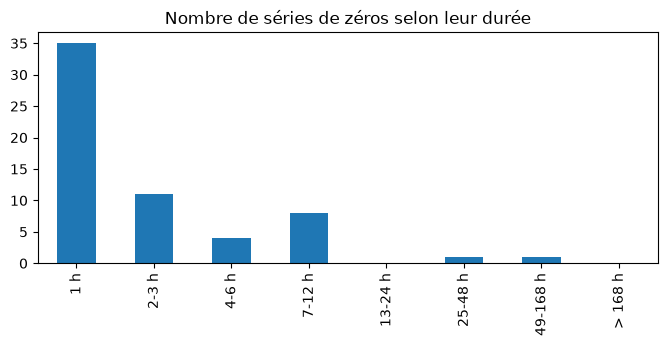

In [10]:
zeros = X == 0
debuts = zeros & ~zeros.shift(fill_value=False)
longueurs = zeros.apply(runs)[debuts].stack().dropna()
etiquettes = ["1 h", "2-3 h", "4-6 h", "7-12 h", "13-24 h", "25-48 h", "49-168 h", "> 168 h"]
repartition = pd.cut(longueurs, bins=[0, 1, 3, 6, 12, 24, 48, 168, np.inf], labels=etiquettes).value_counts().reindex(etiquettes)
print(f"{len(longueurs)} séries de zéros ; {int(zeros.sum().sum())} heures à zéro ; dont {int(zeros_long.sum().sum())} dans des séries >= {ZERO_H} h")
ax = repartition.plot.bar(figsize=(8, 3), title="Nombre de séries de zéros selon leur durée")
repartition.to_frame("nb_series")

**Observation** : 295 heures à zéro réparties en 60 séries : 35 de 1 h, 11 de 2 à 3 h, 4 de 4 à 6 h, 8 de 7 à 12 h, aucune de 13 à 24 h, 1 de 25 à 48 h et 1 de 49 à 168 h. Les 20 bâtiments ont une consommation moyenne strictement positive.  **Décision** : `ZERO_H` = 1 h : tout zéro est une donnée manquante.  **Justification** : les auteurs de BDG2 retirent exactement ces 295 zéros (rappel de 100 %) ; une consommation nulle pendant une heure dans un bâtiment occupé est une panne de compteur ou une absence de donnée. Les 46 séries de 1 à 3 h seront interpolées (≤ 3 h) ; les 14 séries plus longues restent en NaN.

### Durée des plateaux : le seuil `FIGE_H`

La règle « valeur figée » retire les séries d'heures où la mesure ne bouge pas. Mais un compteur de **faible résolution** (par exemple arrondi à l'unité) affiche légitimement des plateaux. Avec `FIGE_H = 6`, la première exécution a retiré **10 289 points, dont aucun n'est retiré par les auteurs** (8 853 pour un seul bâtiment, qui perdait 54 % de ses données). On regarde donc combien de points sont retirés selon la durée minimale d'un plateau, et quelles valeurs forment ces plateaux.

In [11]:
figes_brut = (X.diff() == 0) & (X != 0)
valeurs_fige = [6, 12, 24, 48, 72, 168]
sens_fige = pd.Series({h: int((figes_brut.apply(runs) >= h).sum().sum()) for h in valeurs_fige}, name="nb_points")
par_batiment = pd.DataFrame({h: (figes_brut.apply(runs) >= h).sum() for h in (6, 24, 72)})
print("Points retirés selon FIGE_H (tous bâtiments) :"); display(sens_fige.to_frame())
print("Les 5 bâtiments les plus touchés, selon FIGE_H :"); display(par_batiment.sort_values(6, ascending=False).head(5))
pire_fige = par_batiment[6].idxmax()
plateaux = X[pire_fige][figes_brut[pire_fige]]
print(pire_fige, ": valeurs les plus fréquentes dans les plateaux (une valeur dominante = compteur à faible résolution) :")
display(plateaux.value_counts().head(5).to_frame("nb_heures"))
faible_resolution = X.columns[X.nunique() < FIGE_RESOLUTION_MIN].tolist()
print("Bâtiments à faible résolution (exemptés de la règle « figé ») :", faible_resolution)

Points retirés selon FIGE_H (tous bâtiments) :


,nb_points
6,94
12,94
24,94
48,94
72,94
168,0


Les 5 bâtiments les plus touchés, selon FIGE_H :


,6,24,72
Fox_office_Margarita,94,94,94
Fox_lodging_Stephen,0,0,0
Fox_education_Andre,0,0,0
Fox_education_Charles,0,0,0
Fox_office_Berniece,0,0,0


Fox_office_Margarita : valeurs les plus fréquentes dans les plateaux (une valeur dominante = compteur à faible résolution) :


,nb_heures
Fox_office_Margarita,
25.56,94
15.01,3
8.19,3
15.26,2
23.66,2


Bâtiments à faible résolution (exemptés de la règle « figé ») : []


**Observation** : seulement 94 points sont retirés pour toute durée de plateau de 6 à 72 h, et 0 à 168 h : un seul bâtiment est touché, `Fox_office_Margarita` (94 h consécutives à 25,56 kWh), qui compte aussi 170 h de zéros. Aucun bâtiment n'a une faible résolution.  **Décision** : `FIGE_H` = 24 h.  **Justification** : le nombre de points ne dépend pas du seuil entre 6 et 72 h (aucun réglage sensible) ; l'impact est négligeable (94 points, soit 0,03 % des données) ; les vrais compteurs bloqués ont déjà été écartés à la sélection (filtre plateau ≤ 168 h).

## 5. Regarder pour décider : sensibilité du seuil `K`

Si on baisse `K`, on détecte plus de points, dont de **vraies variations** (jours fériés, pics réels). Si on le monte, on laisse passer des défauts. On cherche le « coude » : la zone où le nombre de points détectés cesse de bouger beaucoup.

3     53310
4     36946
5     26821
6     19845
8     10866
10     6824
15     2625
20     1313
Name: nb_points, dtype: int64

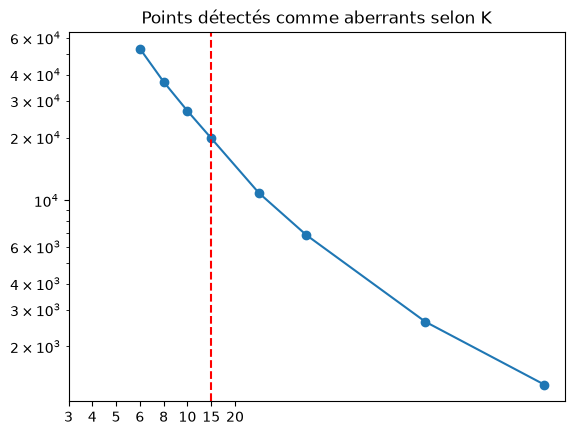

In [12]:
valeurs_k = [3, 4, 5, 6, 8, 10, 15, 20]
sens = pd.Series({k: int((ecart.abs() > k * echelle).sum().sum()) for k in valeurs_k}, name="nb_points")
ax = sens.plot(marker="o", title="Points détectés comme aberrants selon K", logy=True)
ax.axvline(valeurs_k.index(K), color="red", ls="--"); ax.set_xticks(range(len(valeurs_k))); ax.set_xticklabels(valeurs_k)
sens

**Observation** : le nombre de points détectés comme aberrants décroît de façon continue avec K (19 845 à K = 6, 10 866 à K = 8, 6 824 à K = 10, 2 625 à K = 15, 1 313 à K = 20) : il n'y a **pas de coude**, donc pas de séparation nette entre valeurs normales et aberrantes. Les points détectés se concentrent dans les salles d'événements (`Fox_assembly_Kathie`, `Fox_assembly_Carlos`) et correspondent, sur le graphique, à de vrais pics pendant l'année universitaire, absents l'été.

**Décision** : `K` = 15 pour la **détection**, mais `RETIRER_ABERRANTS = False` : les aberrants sont repérés et conservés.

**Justification** : aucun des 2 625 points n'est confirmé par les auteurs ; les retirer effacerait les pics de consommation que le responsable énergie doit précisément anticiper. **Alternative écartée** : K = 6, qui retirerait 5,7 % des données.

In [13]:
def trace_avant_apres(b, debut, fin, nettoye=None):
    """Courbe brute, courbe nettoyée et points détectés par chaque règle."""
    brut = X[b][debut:fin]
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(brut.index, brut.values, color="lightgray", label="raw")
    if nettoye is not None:
        net = nettoye[b][debut:fin]
        ax.plot(net.index, net.values, lw=1, label="nettoyé")
    for nom, mask in [("négatif", negatif), ("zéros longs", zeros_long), ("figé", fige), ("aberrant", aberrant)]:
        pts = brut[mask[b][debut:fin]]
        if len(pts):
            ax.plot(pts.index, pts.values, "o", ms=4, label=nom)
    ax.legend(loc="upper right"); ax.set_title(b); ax.set_ylabel("kWh")

nb_flags = (negatif | zeros_long | fige | aberrant).sum()
pire, meilleur = nb_flags.idxmax(), nb_flags.idxmin()
print("Bâtiment le plus touché :", pire, int(nb_flags[pire]), "points | le moins touché :", meilleur, int(nb_flags[meilleur]))

Bâtiment le plus touché : Fox_assembly_Kathie 561 points | le moins touché : Fox_assembly_Lakeisha 11


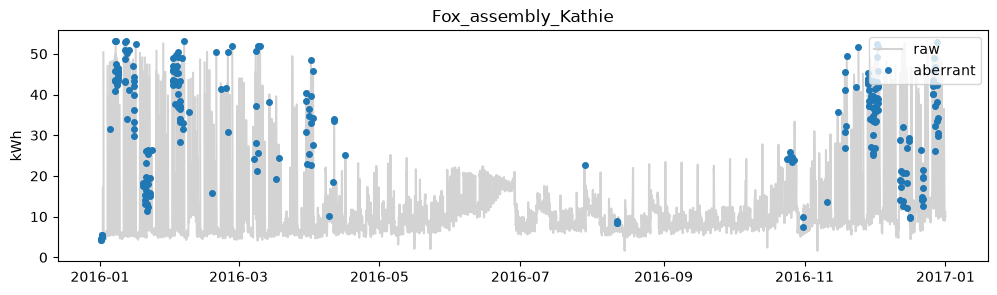

In [14]:
# Vue d'ensemble de l'année 2016 pour le bâtiment le plus touché (chercher un défaut visible)
trace_avant_apres(pire, "2016-01-01", "2016-12-31")

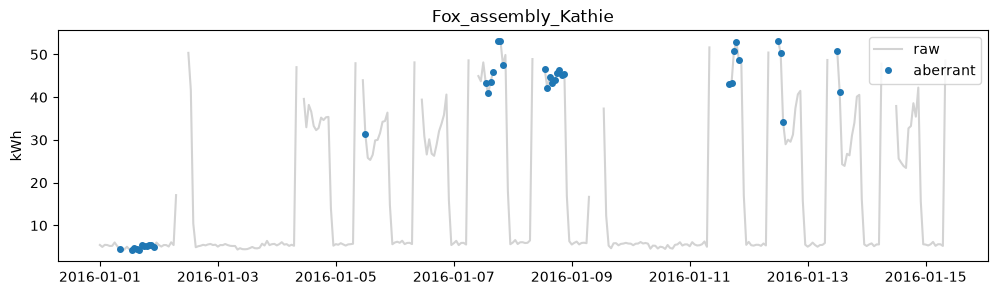

In [15]:
# Zoom sur une période où une règle se déclenche (adapte les dates après avoir regardé le graphique précédent)
premier = (negatif | zeros_long | fige | aberrant)[pire]
date_defaut = premier[premier].index[0] if premier.any() else X.index[0]
trace_avant_apres(pire, date_defaut - pd.Timedelta(days=14), date_defaut + pd.Timedelta(days=14))

### À écrire sous les graphiques (pour l'ADR)

- **Observation** : ce qu'on voit (défauts réels ? fausses alertes ?).
- **Décision** : seuil retenu pour `ZERO_H`, `FIGE_H`, `K`.
- **Justification** : pourquoi pas plus haut, pas plus bas. Montre aussi **un cas où une règle se trompe** (par exemple un jour férié détecté à tort) : c'est ce qui prouve que le seuil vient des graphiques.

## 6. Validation : nos règles retrouvent-elles ce qu'ont retiré les auteurs ?

Le fichier `cleaned` a été produit par les auteurs de BDG2 (voir leur notebook `10_Cleaned-dataset`). On compare, **sans l'utiliser** pour nettoyer :
- *Rappel* : parmi les valeurs qu'ils ont retirées, quelle part retrouvons-nous ?
- *Part en plus* : parmi les valeurs que nous retirons, quelle part n'ont-ils pas retirée ?

Ce n'est pas une vérité absolue : un écart est une **question à examiner**, pas une erreur.

In [16]:
aut = REF.isna() & X.notna()                                   # retiré par les auteurs
nous = negatif | zeros_long | fige | (aberrant if RETIRER_ABERRANTS else aberrant & False)                   # retiré par nos règles

def comparer(nous, aut):
    return {"rappel": (aut & nous).sum().sum() / max(aut.sum().sum(), 1),
            "part_en_plus": (nous & ~aut).sum().sum() / max(nous.sum().sum(), 1),
            "nb_nous": int(nous.sum().sum()), "nb_auteurs": int(aut.sum().sum())}

tab = pd.DataFrame({k: comparer((negatif | zeros_long | fige | (ecart.abs() > k * echelle)), aut) for k in [4, 6, 8, 10]}).T
tab.index.name = "K"
tab

,rappel,part_en_plus,nb_nous,nb_auteurs
K,,,,
4,1.00,0.99,37335.00,295.00
6,1.00,0.99,20234.00,295.00
8,1.00,0.97,11255.00,295.00
10,1.00,0.96,7213.00,295.00


In [17]:
# Par règle : que retire-t-on, et les auteurs l'ont-ils retiré aussi ?
pd.DataFrame({nom: {"nb_points": int(m.sum().sum()), "dont_aussi_retires_par_auteurs": int((m & aut).sum().sum())}
              for nom, m in [("négatif", negatif), ("zéros longs", zeros_long), ("figé", fige), ("aberrant", aberrant)]}).T

,nb_points,dont_aussi_retires_par_auteurs
négatif,0,0
zéros longs,295,295
figé,94,0
aberrant,2625,0


## 7. Correction et traitement des trous

Après détection, on retire les valeurs suspectes (→ NaN) puis on traite les **trous** selon leur longueur :

| Option | Avantage | Limite |
|---|---|---|
| Laisser NaN, exclure ces lignes | aucune invention | perte de lignes ; les retards (veille, semaine passée) manquent autour du trou |
| **Interpoler les trous courts (≤ 3 h)** | continuité, risque faible | seuil à justifier |
| Remplir par la valeur de la semaine passée | respecte le cycle | plus d'hypothèses |
| Exclure le bâtiment | jeu propre | moins de bâtiments |

On retient la 2e option (**proposition**, à valider en groupe). Les trous plus longs restent NaN. Chaque valeur interpolée est marquée `kwh_imputed=True` : **on ne l'évaluera jamais comme une vraie mesure**.

In [18]:
def interpoler_petits_trous(df, max_h):
    """Interpole seulement les trous de longueur <= max_h (les longs restent NaN, entièrement)."""
    longueur = df.isna().apply(runs)
    a_remplir = df.isna() & (longueur <= max_h)
    interpole = df.interpolate(method="time", limit_area="inside")
    return df.where(~a_remplir, interpole), a_remplir & interpole.notna()

Xc = X.mask(nous)                                  # raw sans les valeurs suspectes
Xf, imputed = interpoler_petits_trous(Xc, TROU_INTERP_H)
print("valeurs interpolées :", int(imputed.sum().sum()), "| NaN restants :", int(Xf.isna().sum().sum()))

valeurs interpolées : 400 | NaN restants : 422


In [19]:
rapport = pd.DataFrame({
    "pct_nan_raw": X.isna().mean() * 100,
    "n_negatifs": negatif.sum(), "n_zeros_longs": zeros_long.sum(), "n_figes": fige.sum(), "n_aberrants": aberrant.sum(),
    "n_interpoles": imputed.sum(),
    "pct_nan_final": Xf.isna().mean() * 100,
    "plus_long_trou_final_h": Xf.apply(plus_long_trou),
})
rapport.index.name = "building_id"
rapport.round(2).to_csv(INTERIM / "rapport-nettoyage.csv")
rapport.sort_values("pct_nan_final", ascending=False).head(8)

,pct_nan_raw,n_negatifs,n_zeros_longs,n_figes,n_aberrants,n_interpoles,pct_nan_final,plus_long_trou_final_h
building_id,,,,,,,,
Fox_office_Margarita,0.02,0,170,94,20,6,1.49,103
Fox_assembly_Kathie,1.67,0,9,0,552,224,0.44,7
Fox_office_Berniece,0.02,0,17,0,386,5,0.09,11
Fox_education_Jaclyn,0.09,0,0,0,45,3,0.07,13
Fox_office_Rowena,0.01,0,22,0,73,11,0.07,7
Fox_office_Zachary,0.01,0,15,0,0,5,0.06,11
Fox_assembly_Lakeisha,0.01,0,11,0,0,5,0.04,7
Fox_public_Lauren,0.02,0,7,0,170,3,0.04,7


### Notre nettoyage est-il trop agressif ? Comparaison du taux de NaN

Les auteurs ne retirent, pour ces 20 bâtiments, que les zéros. Si notre jeu contient **beaucoup plus de NaN** que `raw` et que leur `cleaned`, nos règles retirent des valeurs que les auteurs jugent correctes : on revoit `FIGE_H` et `K` avant d'aller plus loin.

In [20]:
bilan = pd.DataFrame({"nan_raw_%": X.isna().mean() * 100, "nan_auteurs_%": REF.isna().mean() * 100, "nan_final_%": Xf.isna().mean() * 100})
print(f"NaN moyen : raw {bilan['nan_raw_%'].mean():.2f} % | cleaned des auteurs {bilan['nan_auteurs_%'].mean():.2f} % | notre jeu {bilan['nan_final_%'].mean():.2f} %")
print("Bâtiments avec plus de 5 % de NaN dans notre jeu :", int((bilan["nan_final_%"] > 5).sum()), "sur", len(bilan))
bilan.sort_values("nan_final_%", ascending=False).head(5)

NaN moyen : raw 0.12 % | cleaned des auteurs 0.21 % | notre jeu 0.12 %
Bâtiments avec plus de 5 % de NaN dans notre jeu : 0 sur 20


,nan_raw_%,nan_auteurs_%,nan_final_%
Fox_office_Margarita,0.02,0.99,1.49
Fox_assembly_Kathie,1.67,1.72,0.44
Fox_office_Berniece,0.02,0.11,0.09
Fox_education_Jaclyn,0.09,0.09,0.07
Fox_office_Rowena,0.01,0.13,0.07


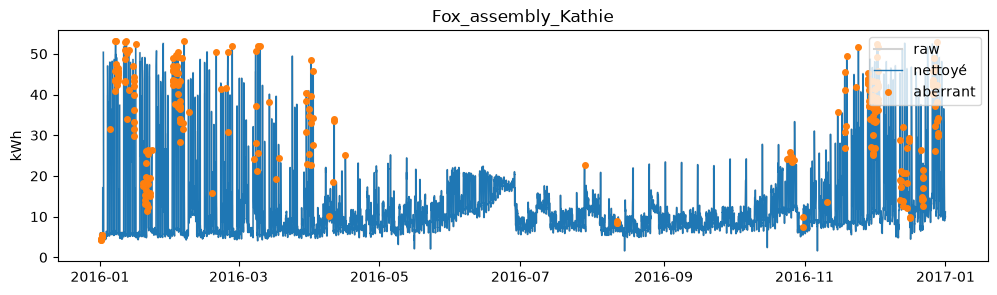

In [21]:
# Résultat sur le bâtiment le plus touché : avant / après
trace_avant_apres(pire, "2016-01-01", "2016-12-31", nettoye=Xf)

Text(0.5, 1.0, 'Valeurs manquantes après nettoyage')

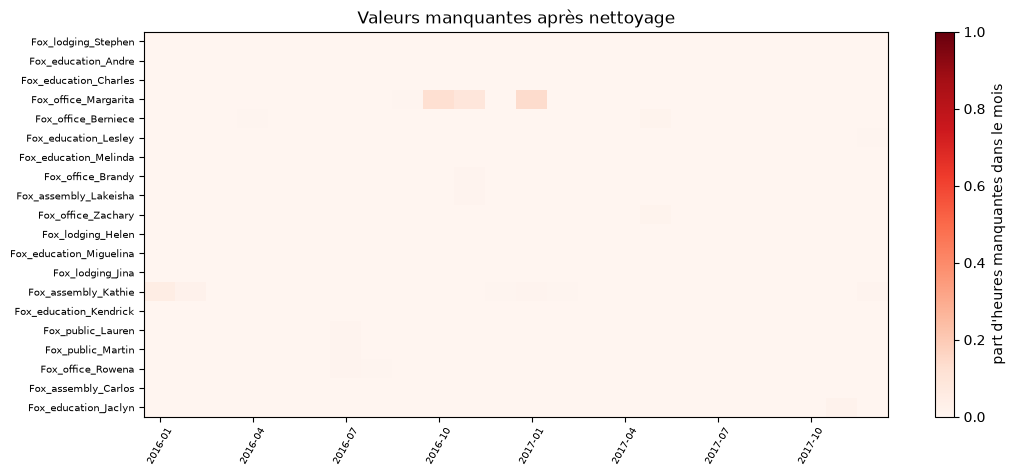

In [22]:
# Carte des valeurs manquantes finales (1 ligne = 1 bâtiment) : repérer trous longs et bâtiments à surveiller
mois = Xf.isna().astype(float).groupby(Xf.index.to_period("M")).mean().T
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(mois.values, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_yticks(range(len(mois.index))); ax.set_yticklabels(mois.index, fontsize=7)
ax.set_xticks(range(0, mois.shape[1], 3)); ax.set_xticklabels([str(p) for p in mois.columns[::3]], rotation=60, fontsize=7)
plt.colorbar(im, label="part d'heures manquantes dans le mois"); ax.set_title("Valeurs manquantes après nettoyage")

## 8. Météo du site

La météo est **mesurée**, pas prévue : en production on n'aura que des prévisions (limite à écrire dans l'étude, section 9). On vérifie : doublons, manquants, plages plausibles, alignement avec les compteurs.

In [23]:
w = pd.read_csv(RAW / "weather.csv", parse_dates=["timestamp"])
w = w[w["site_id"] == SITE]
print("doublons de timestamp :", int(w["timestamp"].duplicated().sum()))
w = w.drop_duplicates("timestamp").set_index("timestamp").sort_index().drop(columns=["site_id"])
w = w.reindex(X.index)                                       # même axe temporel que l'électricité
w.index.name = "timestamp"
print("heures de météo absentes sur ce site (avant interpolation) :", int(w.isna().all(axis=1).sum()))

doublons de timestamp : 0
heures de météo absentes sur ce site (avant interpolation) : 1


In [24]:
w.describe(percentiles=[0.01, 0.5, 0.99]).T    # AVANT nettoyage : repérer les valeurs absurdes (température en °C, nébulosité en oktas, vent, pluie...)

,count,mean,std,min,1%,50%,99%,max
airTemperature,17542.00,25.08,9.15,2.20,6.70,25.60,42.80,48.30
cloudCoverage,12573.00,2.04,1.93,0.00,0.00,2.00,8.00,9.00
dewTemperature,17542.00,3.96,7.57,-19.40,-11.70,3.30,20.60,24.40
precipDepth1HR,17472.00,0.14,2.93,-1.00,-1.00,0.00,0.58,234.00
precipDepth6HR,160.00,17.84,33.52,-1.00,-1.00,3.00,146.40,230.00
seaLvlPressure,17490.00,1011.41,5.19,996.10,1001.10,1010.80,1025.10,1032.20
windDirection,16328.00,153.41,103.75,0.00,0.00,130.00,350.00,360.00
windSpeed,17531.00,2.91,1.95,0.00,0.00,2.60,8.80,15.40


**Valeurs spéciales et plausibilité.** Sur le jeu complet, `precipDepth1HR` contient la valeur **-1** (on la lit comme une « trace » de pluie : **hypothèse**, à traiter comme 0) et des valeurs aberrantes (jusqu'à 597 mm en une heure). Les plages ci-dessous sont **provisoires** : ajuste-les d'après le tableau précédent, puis note-les dans l'ADR.

In [25]:
PLAGES_METEO = {
    "airTemperature": (-60, 60), "dewTemperature": (-60, 40), "seaLvlPressure": (850, 1090),
    "windSpeed": (0, 60), "windDirection": (0, 360), "cloudCoverage": (0, 9),
    "precipDepth1HR": (0, 150), "precipDepth6HR": (0, 400),
}
for col in ("precipDepth1HR", "precipDepth6HR"):
    if col in w:
        w[col] = w[col].where(w[col] != -1, 0.0)           # -1 = trace (hypothèse) -> 0
hors = pd.DataFrame({c: (w[c] < lo) | (w[c] > hi) for c, (lo, hi) in PLAGES_METEO.items() if c in w})
print("valeurs hors plage mises à NaN :"); print(hors.sum()[hors.sum() > 0])
w = w.mask(hors)
print("incohérences (point de rosée > température + 0,5 °C) :", int((w["dewTemperature"] > w["airTemperature"] + 0.5).sum()))
pct_meteo = (w.isna().mean() * 100).round(1)
print("% de NaN par variable météo, après nettoyage :"); print(pct_meteo)

valeurs hors plage mises à NaN :
precipDepth1HR    1
dtype: int64
incohérences (point de rosée > température + 0,5 °C) : 0
% de NaN par variable météo, après nettoyage :
airTemperature    0.00
cloudCoverage    28.30
dewTemperature    0.00
precipDepth1HR    0.40
precipDepth6HR   99.10
seaLvlPressure    0.30
windDirection     6.90
windSpeed         0.10
dtype: float64


In [26]:
gardees = pct_meteo[pct_meteo <= METEO_MAX_NAN].index.tolist()
ecartees = sorted(set(w.columns) - set(gardees))
print("Variables météo gardées :", gardees); print("Écartées (trop de NaN) :", ecartees)
sans_interpolation = ["windDirection"]   # variable circulaire (359° et 1° sont voisins) : une interpolation linéaire serait fausse
a_interpoler = [c for c in gardees if c not in sans_interpolation]
w_interp, w_imputed = interpoler_petits_trous(w[a_interpoler], METEO_INTERP_H)
w_f = w[gardees].copy()
w_f[a_interpoler] = w_interp
print("valeurs de météo interpolées :", int(w_imputed.sum().sum()), "| NaN restants (%) :")
print((w_f.isna().mean() * 100).round(2))

Variables météo gardées : ['airTemperature', 'cloudCoverage', 'dewTemperature', 'precipDepth1HR', 'seaLvlPressure', 'windDirection', 'windSpeed']
Écartées (trop de NaN) : ['precipDepth6HR']
valeurs de météo interpolées : 4964 | NaN restants (%) :
airTemperature   0.00
cloudCoverage    0.40
dewTemperature   0.00
precipDepth1HR   0.36
seaLvlPressure   0.10
windDirection    6.93
windSpeed        0.00
dtype: float64


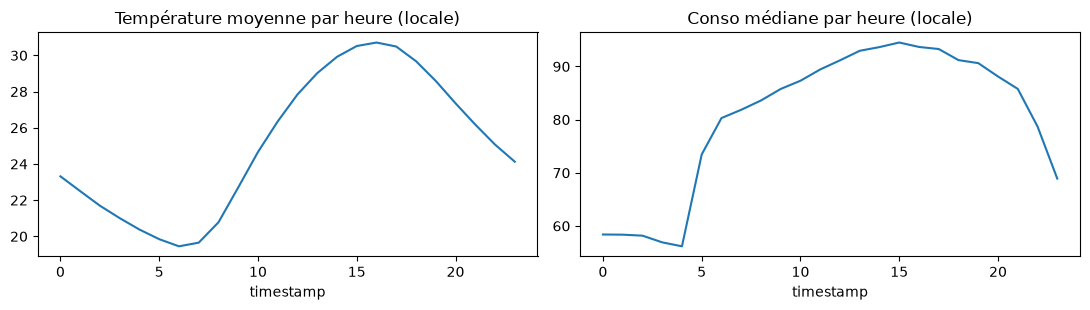

In [27]:
# Alignement : la température doit être maximale en milieu d'après-midi, et la conso suivre un cycle journalier.
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
w_f["airTemperature"].groupby(w_f.index.hour).mean().plot(ax=ax[0], title="Température moyenne par heure (locale)")
Xf.median(axis=1).groupby(Xf.index.hour).mean().plot(ax=ax[1], title="Conso médiane par heure (locale)")
plt.tight_layout()

<Axes: title={'center': 'Conso normalisée par heure : été vs hiver'}, xlabel='timestamp'>

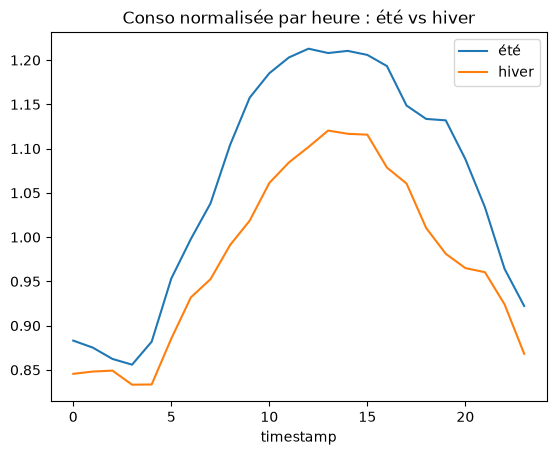

In [28]:
# Heure d'été : le profil du matin est-il décalé d'1 h entre été et hiver ? (à interpréter, pas de réponse automatique)
mediane = Xf.div(Xf.median()).median(axis=1)
ete = mediane[mediane.index.month.isin([6, 7, 8])].groupby(mediane[mediane.index.month.isin([6, 7, 8])].index.hour).median()
hiver = mediane[mediane.index.month.isin([12, 1, 2])].groupby(mediane[mediane.index.month.isin([12, 1, 2])].index.hour).median()
pd.DataFrame({"été": ete, "hiver": hiver}).plot(title="Conso normalisée par heure : été vs hiver")

## 9. Assemblage du jeu final (format long) et contrôles

Une ligne = un bâtiment à une heure. On ajoute les métadonnées et la météo. On garde `kwh_raw` pour la traçabilité.

In [29]:
def en_long(df, nom):
    return df.reset_index().melt(id_vars="timestamp", var_name="building_id", value_name=nom)

long = (en_long(Xf, "kwh")
        .merge(en_long(imputed.astype(bool), "kwh_imputed"), on=["timestamp", "building_id"])
        .merge(en_long(X, "kwh_raw"), on=["timestamp", "building_id"])
        .merge(ids, on="building_id", how="left")
        .merge(w_f.reset_index(), on="timestamp", how="left")
        .sort_values(["building_id", "timestamp"]).reset_index(drop=True))
long["kwh_imputed"] = long["kwh_imputed"].astype(bool)
long.dtypes

timestamp            datetime64[us]
building_id                     str
kwh                         float64
kwh_imputed                    bool
kwh_raw                     float64
site_id                         str
primaryspaceusage               str
sqm                         float64
airTemperature              float64
cloudCoverage               float64
dewTemperature              float64
precipDepth1HR              float64
seaLvlPressure              float64
windDirection               float64
windSpeed                   float64
dtype: object

In [30]:
# Tests intégrés (les mêmes sont dans tests/test_donnees.py pour pytest)
assert len(long) == len(choisis) * len(X), "Nombre de lignes inattendu"
assert not long.duplicated(["building_id", "timestamp"]).any(), "Doublons (bâtiment, heure)"
assert (long["kwh"].dropna() >= 0).all(), "kWh négatifs restants"
assert (long.loc[long["kwh_imputed"], "kwh"].notna()).all(), "Valeur marquée interpolée mais vide"
assert long["site_id"].nunique() == 1, "Plusieurs sites dans le jeu"
nan_temp = long["airTemperature"].isna().mean() * 100
print(f"{len(long):,} lignes · {long['building_id'].nunique()} bâtiments · NaN kwh = {long['kwh'].isna().mean()*100:.2f} % · NaN température = {nan_temp:.2f} %")
assert nan_temp < 10, "Trop de températures manquantes après la jointure : vérifier l'alignement."

350,880 lignes · 20 bâtiments · NaN kwh = 0.12 % · NaN température = 0.00 %


In [31]:
long.to_parquet(PROCESSED / "bdg2_elec_clean.parquet", index=False)
print("Taille :", round((PROCESSED / "bdg2_elec_clean.parquet").stat().st_size / 1e6, 1), "Mo")
long.head()

Taille : 4.3 Mo


,timestamp,building_id,kwh,kwh_imputed,kwh_raw,site_id,primaryspaceusage,sqm,airTemperature,cloudCoverage,dewTemperature,precipDepth1HR,seaLvlPressure,windDirection,windSpeed
0,2016-01-01 00:00:00,Fox_assembly_Carlos,73.89,False,73.89,Fox,Entertainment/public assembly,6706.90,7.20,0.00,-5.60,0.00,1017.30,0.00,0.00
1,2016-01-01 01:00:00,Fox_assembly_Carlos,73.99,False,73.99,Fox,Entertainment/public assembly,6706.90,7.20,0.00,-6.70,0.00,1017.00,50.00,1.50
2,2016-01-01 02:00:00,Fox_assembly_Carlos,75.75,False,75.75,Fox,Entertainment/public assembly,6706.90,6.10,0.00,-5.00,0.00,1016.90,0.00,0.00
3,2016-01-01 03:00:00,Fox_assembly_Carlos,75.55,False,75.55,Fox,Entertainment/public assembly,6706.90,5.00,0.00,-5.60,0.00,1017.40,0.00,0.00
4,2016-01-01 04:00:00,Fox_assembly_Carlos,75.06,False,75.06,Fox,Entertainment/public assembly,6706.90,4.40,0.00,-5.60,0.00,1017.20,0.00,0.00


## 10. Contrat de sortie pour les camarades

Fichier : `data/processed/bdg2_elec_clean.parquet` (hors Git ; DVC en S7). Colonnes :

| Colonne | Contenu |
|---|---|
| `timestamp` | heure locale, pas de 1 h |
| `building_id`, `site_id`, `primaryspaceusage`, `sqm` | identification |
| `kwh` | consommation nettoyée (NaN si trou long) |
| `kwh_imputed` | True si interpolée : à exclure de l'évaluation |
| `kwh_raw` | valeur d'origine (traçabilité) |
| météo | variables retenues, à l'heure |

**Règle de traitement des NaN restants (proposition)** : les lignes dont `kwh` est NaN ou `kwh_imputed` est True sont exclues de l'évaluation, pour tous les modèles, sur les mêmes lignes.

## 11. À recopier dans l'ADR « nettoyage des données »

| Question | Réponse |
|---|---|
| Seuils retenus `ZERO_H`, `FIGE_H`, `K`, `TROU_INTERP_H` | `ZERO_H` = 1 h · `FIGE_H` = 24 h · `K` = 15 pour **détecter** mais `RETIRER_ABERRANTS = False` (conservés) · `TROU_INTERP_H` = 3 h · météo : trous ≤ 6 h interpolés, variables à plus de 40 % de NaN écartées |
| Justification de chaque seuil (graphique, chiffre) | Zéros : 295 retirés, identiques à ceux des auteurs. Figé : 94 points, courbe plate de 6 à 72 h. Aberrants : 2 625 à K = 15, 0 confirmé par les auteurs, aucun coude dans la sensibilité (19 845 à K = 6, 1 313 à K = 20), et ce sont de vrais pics d'événements. Trous : 400 valeurs interpolées (≤ 3 h) |
| Accord avec `cleaned` (rappel, part en plus) | Rappel **100 %** (295 retraits retrouvés sur 295) ; part en plus 24 % (94 points sur 389). Contenu de `raw` identique à `cleaned` sur 350 152 valeurs communes (écart maximal 0) |
| Écarts expliqués | Les 94 points en plus sont un plateau de 94 h dans `Fox_office_Margarita`. Les 2 625 « aberrants » sont des pics d'événements (salles `Fox_assembly_Kathie` et `Carlos`), conservés |
| Bâtiments les plus problématiques | `Fox_office_Margarita` (170 h de zéros, 1,49 % de NaN) et `Fox_assembly_Kathie` (pics d'événements, 1,28 % de valeurs interpolées) ; voir `data/interim/rapport-nettoyage.csv` |
| Heure d'été : constat | Index sans saut (731 jours de 24 h) ; profils d'été et d'hiver de même forme, sans décalage d'une heure : aucune heure d'été visible, cohérent avec l'Arizona (hypothèse non vérifiée) |
| Météo : variables gardées / écartées et pourquoi | Gardées : température, point de rosée, vitesse et direction du vent, pression, nuages, pluie 1 h. Écartée : `precipDepth6HR` (99,1 % de NaN). Précipitation -1 lue comme une trace (0, hypothèse) ; 1 valeur hors plage (pluie 1 h) mise à NaN ; `windDirection` jamais interpolée (angle) ; 4 964 valeurs interpolées |
| NaN restants et règle d'évaluation | 0,12 % de NaN sur `kwh` (422 valeurs), 400 valeurs interpolées marquées `kwh_imputed` ; règle : exclure NaN et `kwh_imputed`, mêmes lignes pour tous les modèles ; 0 bâtiment au-dessus de 5 % de NaN |
